# Supplementary Fig. 2a: power spectral densities of the raw simulated and in vivo traces

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel a of Supplementary Fig. 2 of the paper: power spectral density (PSD) of the raw voltage traces of the in vivo recordings (Marques-Smith Neuropixels, Horvath dense probe) and of the simulated recordings (spontaneous and evoked Neuropixels, dense probe), with power laws (1/f^alpha) fitted to the low frequencies (0-90 Hz). Source data and svg are saved in figures/8_source_data/supp_fig2a/.

**method (as in the paper's notebook supp_fig2_A_validation_psd_raw_traces_revised.ipynb)**
* the synthetic model of the paper's legend (`S: Synthetic`) is **not plotted**: it has no sites in layers other than layer 5 (all 384 sites are in layer 5), so its spectrum is not comparable with that of the other experiments, and the paper's own plotting code does not draw it (no points of its colour in the paper's panel)
* PSD of every recording site in the cortex with the Welch method (1 Hz resolution, Hann window, demeaned traces), computed by `src/pipes/validation/psd/multiprocess.py` (written in `dataset/01_intermediate/psds/psd_raw_*.npy`: power of the sites x frequency): whole raw traces of the dense probes and of Marques-Smith, the first 10 minutes of the spontaneous and evoked Neuropixels (the whole traces do not fit in the memory of the machine)
* sites: Neuropixels: sites of layers 1 to 6; dense probes (Horvath and simulated): the sites of layers 1 and 2/3 of depth 1, 4 and 5 of depth 2, and 6 of depth 3 (the three depths are pooled)
* for each experiment the figure shows the mean over the sites of the log10 power at each frequency (dots) and the power law fitted to the 0-90 Hz band: a linear regression of the log power on the log frequency of each site, averaged over the sites (black lines)

In [1]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
import spikeinterface as si
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# set project path
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(PROJ_PATH)

# custom package
import matplotlib
from sklearn.linear_model import LinearRegression
from matplotlib.lines import Line2D
import re

# paths of the PSDs (power of the sites x frequencies, in uV^2/Hz)
PSD_PATHS = {
    "H": ["dataset/01_intermediate/psds/psd_raw_horvath_probe1.npy", "dataset/01_intermediate/psds/psd_raw_horvath_probe2.npy", "dataset/01_intermediate/psds/psd_raw_horvath_probe3.npy"],
    "NS": ["dataset/01_intermediate/psds/psd_raw_npx_spont.npy"],
    "E": ["dataset/01_intermediate/psds/psd_raw_npx_evoked.npy"],
    "DS": ["dataset/01_intermediate/psds/psd_raw_dense_probe1.npy", "dataset/01_intermediate/psds/psd_raw_dense_probe2.npy", "dataset/01_intermediate/psds/psd_raw_dense_probe3.npy"],
    "M": ["dataset/01_intermediate/psds/psd_raw_marques_smith.npy"],
}
LABELS = {"M": "M : Marques-Smith", "NS": "NS : Biophy. spont.", "E": "E: Biophy. evoked", "H": "H: Horvath", "DS": "DS: Biophy. spont"}
COLORS = {"M": (0.6, 0.6, 0.6), "NS": (0.9, 0.14, 0.15), "E": (1, 0.49, 0), "H": (0.0, 0.0, 0.0), "DS": np.array([26, 152, 80]) / 255}
LFP_BAND = (0, 90)      # Hz, frequency band of the power-law fit

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 1.1
plt.rcParams["axes.linewidth"] = 1
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
legend_cfg = {"frameon": False, "handletextpad": 0.5}

# save config
savefig_cfg = {"transparent": True, "dpi": 300}# paths
DATA_PATH = "dataset/01_intermediate/supplementary/lfp_validation/lfp_infinitesimal_vs_finite.csv"

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 1.1
plt.rcParams["axes.linewidth"] = 1
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
legend_cfg = {"frameon": False, "handletextpad": 0.5}

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

## Load the power spectral densities

In [2]:
%%time

psd = {}
for experiment, paths in PSD_PATHS.items():
    parts = [np.load(p, allow_pickle=True).item() for p in paths]
    assert all(p["freq"][1] == 1.0 for p in parts), "psd resolution should be 1 Hz"
    psd[experiment] = {"power": np.vstack([p["power"] for p in parts]), "freq": parts[0]["freq"]}
    print(f"{experiment:3s} sites: {psd[experiment]['power'].shape[0]:4d} | frequencies: {len(psd[experiment]['freq'])} (up to {psd[experiment]['freq'][-1]:.0f} Hz)")

H   sites:  272 | frequencies: 10001 (up to 10000 Hz)
NS  sites:  202 | frequencies: 20001 (up to 20000 Hz)
E   sites:  202 | frequencies: 10001 (up to 10000 Hz)
DS  sites:  297 | frequencies: 10001 (up to 10000 Hz)
M   sites:  226 | frequencies: 15001 (up to 15000 Hz)
CPU times: user 3.79 ms, sys: 26 ms, total: 29.8 ms
Wall time: 29.8 ms


## Mean log power and power-law fit of each experiment

In [3]:
%%time

points, fits = [], []
for experiment, p in psd.items():
    freq, power = p["freq"], p["power"]
    keep = (freq > 0) & np.isfinite(np.log10(freq))
    log_freq, log_power = np.log10(freq[keep]), np.log10(power[:, keep])
    points.append(pd.DataFrame({"experiment": LABELS[experiment], "frequency_Hz": freq[keep], "log10_power_mean_over_sites": log_power.mean(axis=0)}))

    # power law (1/f^alpha) of each site in the 0-90 Hz band: log10 power = -alpha x log10 frequency + intercept
    band = (freq[keep] > LFP_BAND[0]) & (freq[keep] <= LFP_BAND[1])
    coefs, intercepts = [], []
    for site in range(power.shape[0]):
        reg = LinearRegression().fit(log_freq[band].reshape(-1, 1), log_power[site, band])
        coefs.append(reg.coef_[0]); intercepts.append(reg.intercept_)
    fits.append(dict(experiment=LABELS[experiment], n_sites=power.shape[0], slope_mean=np.mean(coefs), slope_std=np.std(coefs), intercept_mean=np.mean(intercepts),
                     band_low_Hz=float(freq[keep][band].min()), band_high_Hz=float(freq[keep][band].max())))
df_points, df_fits = pd.concat(points, ignore_index=True), pd.DataFrame(fits)
display(df_fits.round(3))

<timed exec>:4: RuntimeWarning: divide by zero encountered in log10
<timed exec>:4: RuntimeWarning: divide by zero encountered in log10
<timed exec>:4: RuntimeWarning: divide by zero encountered in log10
<timed exec>:4: RuntimeWarning: divide by zero encountered in log10


<timed exec>:4: RuntimeWarning: divide by zero encountered in log10


,experiment,n_sites,slope_mean,slope_std,intercept_mean,band_low_Hz,band_high_Hz
0,H: Horvath,272,-2.272,0.177,5.162,1.0,90.0
1,NS : Biophy. spont.,202,-0.315,0.033,-1.308,1.0,90.0
2,E: Biophy. evoked,202,-0.584,0.241,-0.335,1.0,90.0
3,DS: Biophy. spont,297,-0.301,0.048,-0.613,1.0,90.0
4,M : Marques-Smith,226,-0.606,0.144,-0.972,1.0,90.0


CPU times: user 302 ms, sys: 9.85 ms, total: 312 ms
Wall time: 311 ms


## Plot, same as the paper's panel a

In [4]:
def plot_source_data(df_points: pd.DataFrame, df_fits: pd.DataFrame):
    """Mean power spectral density of the raw traces of each experiment (dots) and power law fitted to 0-90 Hz (black lines)"""

    fig, ax = plt.subplots(1, 1, figsize=(1.2, 1.2))
    inv = {v: k for k, v in LABELS.items()}
    for name in [LABELS[k] for k in ["H", "NS", "E", "DS", "M"]]:
        d = df_points[df_points["experiment"] == name]
        ax.plot(d["frequency_Hz"], 10 ** d["log10_power_mean_over_sites"], color=COLORS[inv[name]], linestyle="None", marker="o", markersize=1.5,
                markeredgecolor="w", markeredgewidth=0.06, rasterized=True)
        f = df_fits[df_fits["experiment"] == name].iloc[0]
        log_f = np.log10(d[(d["frequency_Hz"] > f["band_low_Hz"]) & (d["frequency_Hz"] <= f["band_high_Hz"])]["frequency_Hz"].values)
        ax.plot(10 ** log_f, 10 ** (log_f * f["slope_mean"] + f["intercept_mean"]), color="k", linewidth=0.5)

    # aesthetics
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Normalzed power (ratio)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.xaxis.set_major_locator(matplotlib.ticker.LogLocator(base=10, numticks=4))
    ax.xaxis.set_minor_locator(matplotlib.ticker.LogLocator(base=10.0, subs=(0.2, 0.4, 0.6, 0.8), numticks=12))
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

    # disconnect axes (R style)
    ax.spines["bottom"].set_position(("axes", -0.05)); ax.yaxis.set_ticks_position("left"); ax.spines["left"].set_position(("axes", -0.05))

    # legend below the axes
    handles = [Line2D([], [], marker="o", color="w", markerfacecolor=COLORS[k], markersize=3, label=LABELS[k]) for k in ["M", "NS", "E", "H", "DS"]]
    handles.append(Line2D([], [], color="k", linewidth=0.8, label="Power law fit"))
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(-0.1, -0.5), frameon=False, handletextpad=0.1, labelspacing=0.2, fontsize=4.5)
    return fig, ax

## Plot and save the figure and the source data

CPU times: user 2.01 s, sys: 23.9 ms, total: 2.04 s
Wall time: 2.04 s


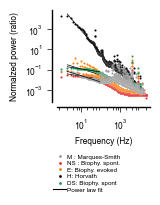

In [5]:
%%time

# plot
fig, ax = plot_source_data(df_points, df_fits)

# save figure
os.makedirs("figures/8_source_data/supp_fig2a", exist_ok=True)
plt.savefig("figures/8_source_data/supp_fig2a/supp_fig2a.svg", bbox_inches="tight", **savefig_cfg)

# save source data (sheet 1: mean log power at each frequency; sheet 2: power-law fits)
with pd.ExcelWriter("figures/8_source_data/supp_fig2a/supp_fig2a.xlsx") as writer:
    df_points.to_excel(writer, sheet_name="psd_mean_over_sites", index=False)
    df_fits.to_excel(writer, sheet_name="power_law_fits", index=False)

## Check: replot from the saved source data

CPU times: user 1.08 s, sys: 12.1 ms, total: 1.09 s
Wall time: 1.08 s


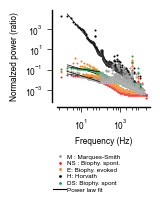

In [6]:
%%time

df_points = pd.read_excel("figures/8_source_data/supp_fig2a/supp_fig2a.xlsx", sheet_name="psd_mean_over_sites")
df_fits = pd.read_excel("figures/8_source_data/supp_fig2a/supp_fig2a.xlsx", sheet_name="power_law_fits")
fig, ax = plot_source_data(df_points, df_fits)